<center><h1> IFT-6758  Science des Données  </h1></center>
<center><h2> Automne - 2022 </h2></center>
<center><h3> Labo - 6</h3></center>
<center><h3> </h3></center>
<center><h3> scikit-learn (3) </h3></center>



### Import

In [17]:
import sklearn

#Other imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Scikit-learn possède une collection de classes qui peuvent être utilisées pour générer des listes d'indices d'entraînement/test pour les stratégies de validation croisée populaires.

Ils exposent une méthode de fractionnement qui accepte l'ensemble de données d'entrée à fractionner et donne les indices d'ensemble d'entraînement/test pour chaque itération de la stratégie de validation croisée choisie.

<a rel="K fold Cross Val">![](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)</a>

In [18]:
# For this exercise we're using a toy dataset:
X = np.array(range(10))
y = np.array(["a", "a", "b", "b", "c", "c", "c", "c", "c", "c"])

K-Fold

In [19]:
from sklearn.model_selection import KFold

k_fold = KFold(n_splits=2, shuffle=False)

for train_indices, test_indices in k_fold.split(X, y):
  print('train y: %s | test y: %s' % (X[train_indices], y[test_indices]))

train y: [5 6 7 8 9] | test y: ['a' 'a' 'b' 'b' 'c']
train y: [0 1 2 3 4] | test y: ['c' 'c' 'c' 'c' 'c']


### K-Fold Stratifié

![](https://miro.medium.com/max/562/0*QKJTHrcriSx2ZNYr.png)



In [20]:
from sklearn.model_selection import StratifiedKFold

stratified_k_fold = StratifiedKFold(n_splits=2, shuffle=True)

for train_indices, test_indices in stratified_k_fold.split(X, y):
  print('train y: %s | test y: %s' % (X[train_indices], y[test_indices]))

train y: [1 2 4 6 9] | test y: ['a' 'b' 'c' 'c' 'c']
train y: [0 3 5 7 8] | test y: ['a' 'b' 'c' 'c' 'c']


# [2] Recherche d'hyperparamètres

### (a) Grid Search

scikit-learn fournit un objet qui, compte tenu des données, calcule le score lors de l'ajustement d'un estimateur sur une grille de paramètres et choisit les paramètres pour maximiser le score de validation croisée. Cet objet prend un estimateur lors de la construction et expose un API d'estimateur :

In [21]:
from sklearn import datasets

# Loading the Digits dataset
digits = datasets.load_digits()

# To apply an classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
X = digits.images.reshape((n_samples, -1))
y = digits.target

X[9] = 


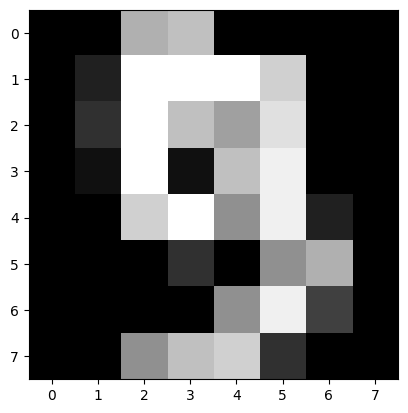

y = [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]


In [22]:
# What is the 'digits' dataset?
from matplotlib import pyplot as plt
idx = 9
print(f'X[{idx}] = ')
plt.imshow(digits.images[idx], cmap='gray')
plt.show()
print(f'y = {y[:20]}')

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.svm import SVC

# Split the dataset in two equal parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0)

# Set the parameters by cross-validation
tuned_parameters = [
  {'kernel': ['rbf'],
  'gamma': [1e-3, 1e-4],
  'C': [1, 10, 100, 1000]},

  {'kernel': ['linear'],
   'C': [1, 10, 100, 1000]},
]

metric = 'f1_macro'

cv_strategy = StratifiedKFold(n_splits=10, shuffle=True)

grid_search = GridSearchCV(
    SVC(), tuned_parameters, scoring=metric, cv=cv_strategy
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [24]:
print("Best parameters set found on development set:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Best parameters set found on development set:

{'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
0.9853634576637674


In [25]:
print("Grid scores on development set:")
print()
means = grid_search.cv_results_['mean_test_score']
stds = grid_search.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, grid_search.cv_results_['params']):
    print("%0.3f (+/-%0.03f) for %r"
          % (mean, std * 2, params))

Grid scores on development set:

0.983 (+/-0.023) for {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
0.956 (+/-0.046) for {'C': 1, 'gamma': 0.0001, 'kernel': 'rbf'}
0.985 (+/-0.020) for {'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
0.982 (+/-0.018) for {'C': 10, 'gamma': 0.0001, 'kernel': 'rbf'}
0.985 (+/-0.020) for {'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}
0.985 (+/-0.025) for {'C': 100, 'gamma': 0.0001, 'kernel': 'rbf'}
0.985 (+/-0.020) for {'C': 1000, 'gamma': 0.001, 'kernel': 'rbf'}
0.985 (+/-0.025) for {'C': 1000, 'gamma': 0.0001, 'kernel': 'rbf'}
0.975 (+/-0.020) for {'C': 1, 'kernel': 'linear'}
0.975 (+/-0.020) for {'C': 10, 'kernel': 'linear'}
0.975 (+/-0.020) for {'C': 100, 'kernel': 'linear'}
0.975 (+/-0.020) for {'C': 1000, 'kernel': 'linear'}


In [26]:
print("Detailed classification report:")
print()
print("The model is trained on the full development set.")
print("The scores are computed on the full evaluation set.")
print()
y_true, y_pred = y_test, grid_search.predict(X_test)
print(classification_report(y_true, y_pred))
print()

Detailed classification report:

The model is trained on the full development set.
The scores are computed on the full evaluation set.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        89
           1       0.97      1.00      0.98        90
           2       0.99      0.98      0.98        92
           3       1.00      0.99      0.99        93
           4       1.00      1.00      1.00        76
           5       0.99      0.98      0.99       108
           6       0.99      1.00      0.99        89
           7       0.99      1.00      0.99        78
           8       1.00      0.98      0.99        92
           9       0.99      0.99      0.99        92

    accuracy                           0.99       899
   macro avg       0.99      0.99      0.99       899
weighted avg       0.99      0.99      0.99       899




### (b) RandomGridSearchCV

Est-ce qu'on peut améliorer avec une recherche aléatoire?

In [27]:
from sklearn.model_selection import RandomizedSearchCV

# How large is this parameter space?
tuned_parameters = [
  {'kernel': ['rbf'],
  'gamma': np.logspace(-3, -4, num=50),
  'C': np.logspace(0, 3, num=50)},

  {'kernel': ['linear'],
   'C': np.logspace(0, 3, num=50)},
]

grid_search = RandomizedSearchCV(
    SVC(), tuned_parameters, n_iter=12, scoring=metric, cv=cv_strategy,
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [28]:
print("Best parameters set found on development set:")
print()
print(grid_search.best_params_)

Best parameters set found on development set:

{'kernel': 'rbf', 'gamma': np.float64(0.0006551285568595509), 'C': np.float64(3.5564803062231287)}


In [29]:
print("Detailed classification report:")
print()
print("The model is trained on the full development set.")
print("The scores are computed on the full evaluation set.")
print()
y_true, y_pred = y_test, grid_search.predict(X_test)
print(classification_report(y_true, y_pred))
print()

Detailed classification report:

The model is trained on the full development set.
The scores are computed on the full evaluation set.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        89
           1       0.97      1.00      0.98        90
           2       0.99      0.99      0.99        92
           3       0.98      0.99      0.98        93
           4       1.00      1.00      1.00        76
           5       0.98      0.98      0.98       108
           6       0.99      1.00      0.99        89
           7       1.00      1.00      1.00        78
           8       1.00      0.95      0.97        92
           9       0.99      0.99      0.99        92

    accuracy                           0.99       899
   macro avg       0.99      0.99      0.99       899
weighted avg       0.99      0.99      0.99       899




# [5] Pipelining

Pipeline peut être utilisé pour enchaîner plusieurs estimateurs en un seul.

Ceci est utile car il y a souvent une séquence fixe d'étapes dans le traitement des données, par exemple la sélection des caractéristiques, la normalisation et la classification. Pipeline a plusieurs objectifs ici :

* *Commodité et encapsulation* - besoin d'appeler fit et de prédire une fois sur vos données

* *Sélection conjointe des paramètres* - peut effectuer une recherche de grille sur les paramètres de tous les estimateurs à la fois.

* *Sécurité* - Évitez les fuites de statistiques de vos données de test dans le modèle formé lors de la validation croisée

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV


# Define a pipeline to search for the best combination of PCA truncation
# and classifier regularization.
pca = PCA()

# set the tolerance to a large value to make the example faster
logistic = LogisticRegression(max_iter=10000, tol=0.1)

pipe = Pipeline(steps=[
  ('pca', pca),
  ('logistic', logistic)
])

X, y = datasets.load_digits(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0)

# Parameters of pipelines can be set using ‘__’ separated parameter names:
param_grid = {
    'pca__n_components': [5, 15, 30, 45, 64],
    'logistic__C': np.logspace(-4, 4, 4),
}

search = GridSearchCV(pipe, param_grid, n_jobs=-1)
search.fit(X_train, y_train);

In [31]:
print("Best parameter (CV score=%0.3f):" % search.best_score_)
print(search.best_params_)

Best parameter (CV score=0.945):
{'logistic__C': np.float64(21.54434690031882), 'pca__n_components': 45}


In [32]:
y_true, y_pred = y_test, grid_search.predict(X_test)
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        89
           1       0.97      1.00      0.98        90
           2       0.99      0.99      0.99        92
           3       0.98      0.99      0.98        93
           4       1.00      1.00      1.00        76
           5       0.98      0.98      0.98       108
           6       0.99      1.00      0.99        89
           7       1.00      1.00      1.00        78
           8       1.00      0.95      0.97        92
           9       0.99      0.99      0.99        92

    accuracy                           0.99       899
   macro avg       0.99      0.99      0.99       899
weighted avg       0.99      0.99      0.99       899



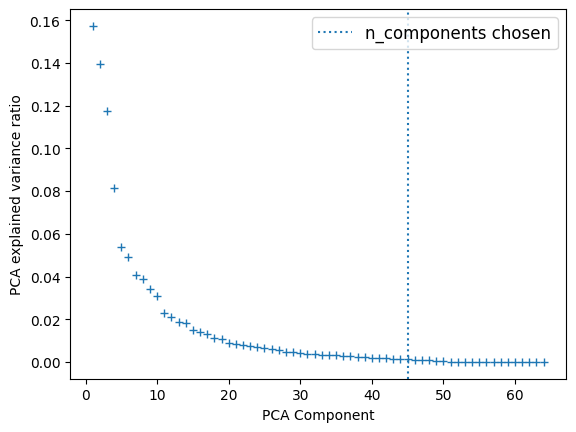

In [33]:
# Plot the PCA spectrum
pca.fit(X_train)


plt.plot(np.arange(1, pca.n_components_ + 1),
         pca.explained_variance_ratio_, '+', linewidth=2)
plt.ylabel('PCA explained variance ratio')
plt.xlabel('PCA Component')

plt.axvline(search.best_estimator_.named_steps['pca'].n_components,
            linestyle=':', label='n_components chosen')
plt.legend(prop=dict(size=12));

In [34]:
pipe.fit(X_test, y_test)

Pipeline(steps=[('pca', PCA()),
                ('logistic', LogisticRegression(max_iter=10000, tol=0.1))])

#[6] Inférence statistique : Bootstrapping et les Intervalles de Confiance

##(a) Intervalle de Confiance pour l'exactitude d'un classifieur

In [35]:
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [36]:
data = pd.read_csv('https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/diabetes.csv', header=None)
values = data.values

In [37]:
values.shape

(768, 9)

In [38]:
values[0] # 8 features ---> 1 output label (0/1)

array([  6.   , 148.   ,  72.   ,  35.   ,   0.   ,  33.6  ,   0.627,
        50.   ,   1.   ])

Fonction Sklearn utilisé pour Bootstrapping : `resample()` [Voir documentation](https://scikit-learn.org/stable/modules/generated/sklearn.utils.resample.html)

In [39]:
# Bootstrap configuration
num_iterations = 1000
num_samples = int(len(data)/ 2)    # Pick a training set with size of 50% of the dataset

In [40]:
# Run the bootstrap
scores = []

for i in range(num_iterations):

  # Prepare train and test sets
  train = resample(values, n_samples=num_samples)
  test = pd.concat([data,pd.DataFrame(train)]).drop_duplicates(keep=False).values            #Consider all the samples other than those in the train set as test set

	# Fit model
  model = DecisionTreeClassifier()
  model.fit(train[:,:-1], train[:,-1])

  # Evaluate model
  predictions = model.predict(test[:,:-1])
  score = accuracy_score(test[:,-1], predictions)

  scores.append(score)

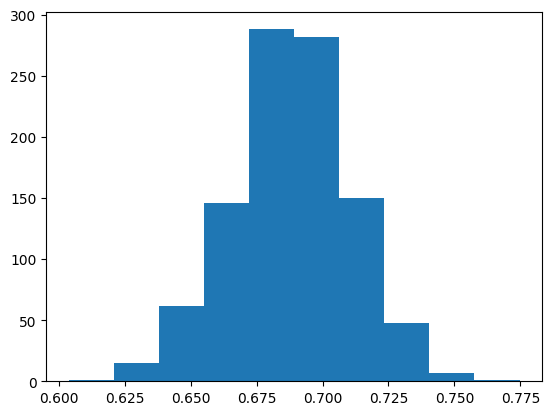

In [41]:
# plot scores
plt.hist(scores);

In [42]:
# Confidence interval

confidence_percentage = 95

# p-values
p = (100-confidence_percentage)/2

# Quartiles
lower = max(0.0, np.percentile(scores, p))
upper = min(1.0, np.percentile(scores, 100 - p))

print('Classifier Accuracy : ({:d}%) confidence interval = [{:.1f}%,{:.1f}%]'.format(int(confidence_percentage), lower*100, upper*100))

Classifier Accuracy : (95%) confidence interval = [64.3%,73.1%]


Visualizer l'intervalle des résultats du bootstrap

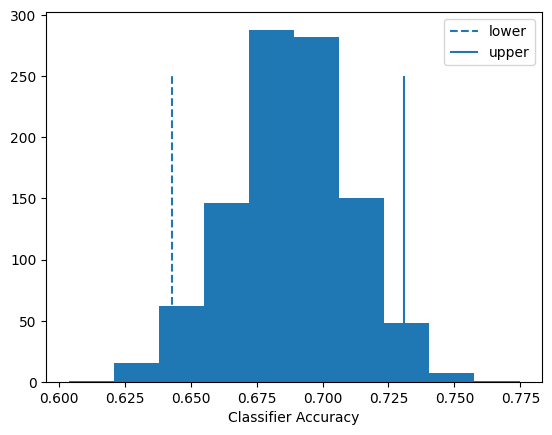

In [43]:
plt.vlines(lower,0,250, linestyles='--', label='lower')
plt.vlines(upper,0,250, label='upper')
plt.xlabel('Classifier Accuracy')
plt.legend(loc='best')
plt.hist(scores);

##(b) Visualizer le CI d'une régression linéaire

In [44]:
from sklearn.linear_model import LinearRegression

In [45]:
num_iterations = 1000

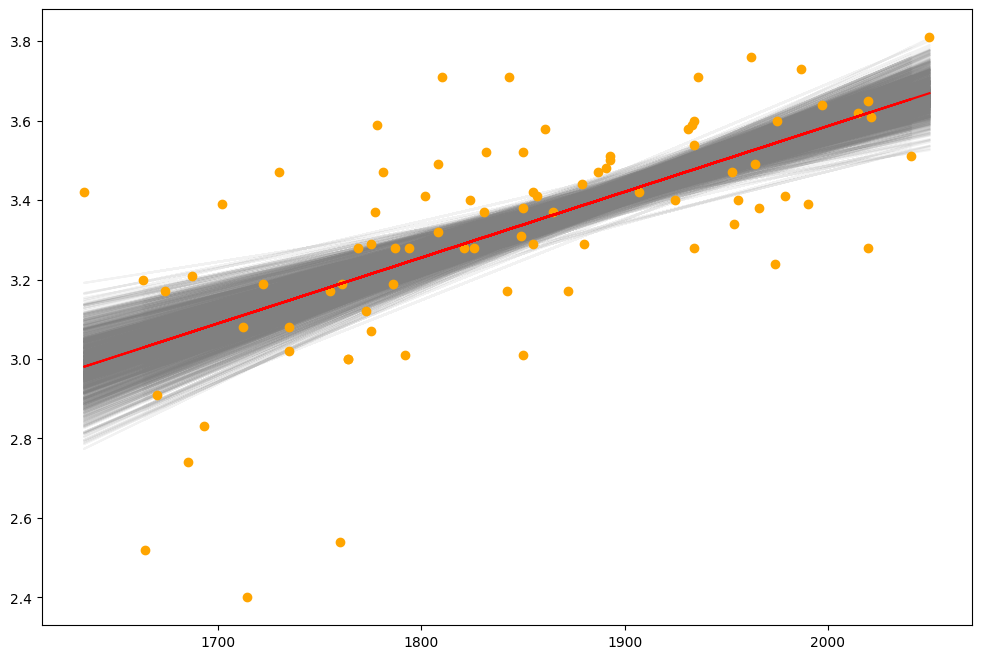

In [46]:

# Load data into dataframe
sat_gpa = pd.read_csv('https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/sat-gpa.csv')
X,y = sat_gpa.SAT.values, sat_gpa.GPA.values

# Reshape X to prepare it for regression
X = X.reshape(-1,1)

plt.figure(figsize=(12,8))


# Bootstrapping loop
for i in range(0, num_iterations):

    sampled_index = np.random.choice(range(0, len(y)), len(y))

    X_samples = X[sampled_index]
    y_samples = y[sampled_index]

    lr = LinearRegression()
    lr.fit(X_samples, y_samples)
    plt.plot(X, lr.predict(X), color='grey', alpha=0.1, zorder=1)

# Plot the data points
plt.scatter(X,y, marker='o', color='orange', zorder=4)

# Fit Regression model for the entre data
lr = LinearRegression()
lr.fit(X, y)
plt.plot(X, lr.predict(X), color='red', zorder=5);

In [47]:
lr.coef_

array([0.00165569])

In [48]:
lr.intercept_

np.float64(0.2750402996602799)

Observez l'étendue du coéefficient de la ligne de régression dans le tracé tel que défini par les lignes de régression bootstrap.

Pour être plus quantitatif:  

In [49]:
from scipy.stats import linregress

X,y = sat_gpa.SAT.values, sat_gpa.GPA.values
slope, intercept, r, p, stderr = linregress(X.squeeze(),y)

print(r)
print(p)
print(stderr)

0.6371843648401914
7.199518436563902e-11
0.0002211557670340503


# TITANIC

# Pipeline de Science des Données

<img src='https://miro.medium.com/max/1400/1*CyK1miQfy1OHmv2wUcjT1w.png'>

# Inspecting Titanic Dataset


[Titanic Kaggle Competition](https://www.kaggle.com/c/titanic/overview)


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#### Download the dataset files

In [51]:
!wget -q https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/titanic-train.csv -O train.csv
!wget -q https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/titanic-test.csv -O test.csv

#### Load the data into DataFrames

In [52]:
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

#### Get DataFrame info

In [53]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**pclass**: A proxy for socio-economic status (SES)
1st = Upper
2nd = Middle
3rd = Lower

**age**: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5

**sibsp**: The dataset defines family relations in this way...
Sibling = brother, sister, stepbrother, stepsister
Spouse = husband, wife (mistresses and fiancés were ignored)

**parch**: The dataset defines family relations in this way...
Parent = mother, father
Child = daughter, son, stepdaughter, stepson
Some children travelled only with a nanny, therefore parch=0 for them.

In [54]:
df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


How many feature variables to we have?

Which is the target variable here?

#### Inspect for null values

In [55]:
df_train.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [56]:
# df_test.isnull().sum()

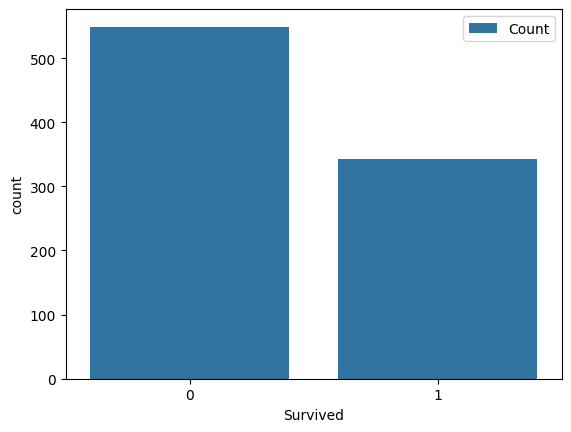

In [57]:
#Visualize the count of number of survivors
sns.countplot(x='Survived', label="Count", data=df_train);

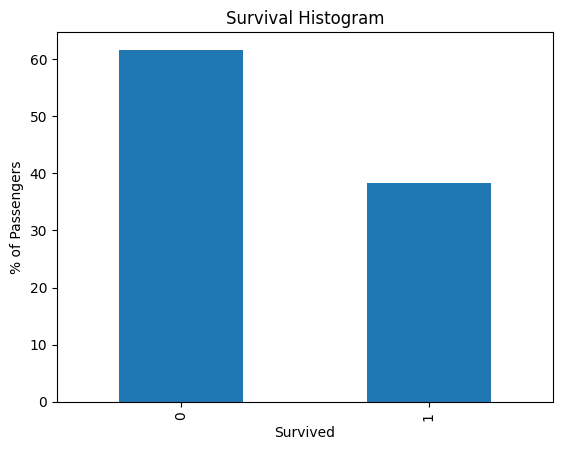

In [58]:
(df_train["Survived"].value_counts(normalize=True)*100).plot(kind="bar")
plt.title("Survival Histogram")
plt.ylabel("% of Passengers")
plt.xlabel("Survived")
plt.show();

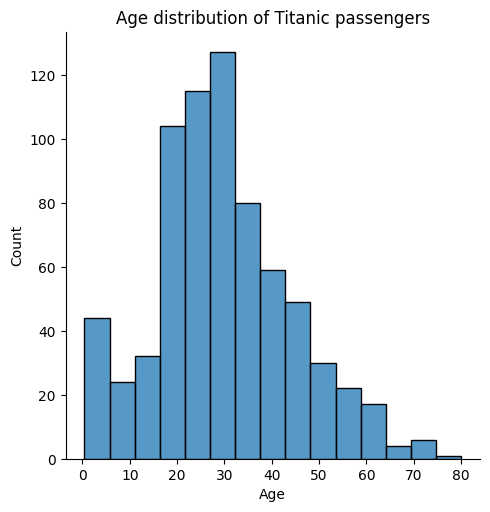

In [59]:
sns.displot(df_train['Age'].dropna(), bins=15, kde=False)
plt.ylabel('Count')
plt.title('Age distribution of Titanic passengers');

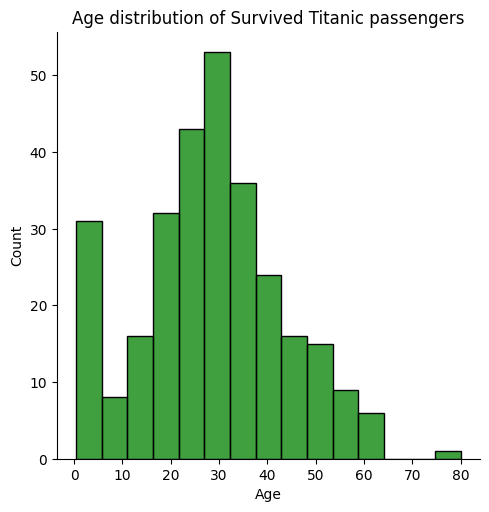

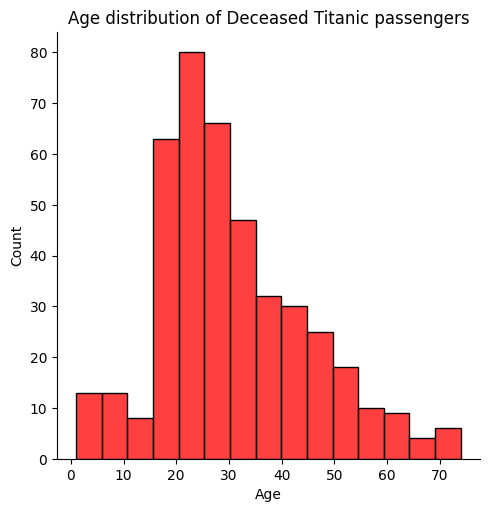

In [60]:
sns.displot(df_train[df_train['Survived']==1]['Age'].dropna(), bins=15, kde=False, color='green')
plt.title('Age distribution of Survived Titanic passengers');
sns.displot(df_train[df_train['Survived']==0]['Age'].dropna(), bins=15, kde=False, color='red')
plt.ylabel('Count')
plt.title('Age distribution of Deceased Titanic passengers');

/tmp/ipython-input-1978906443.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 0], label="Perished", shade=True, color="red")
/tmp/ipython-input-1978906443.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 1], label="Survived", shade=True, color="green")


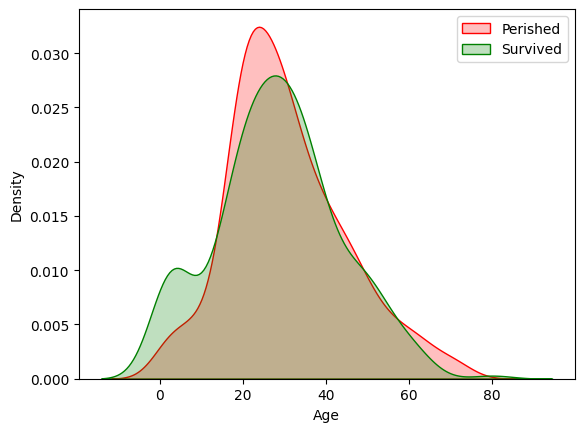

In [61]:
g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 0], label="Perished", shade=True, color="red")
g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 1], label="Survived", shade=True, color="green")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()

#### Exploring outliers

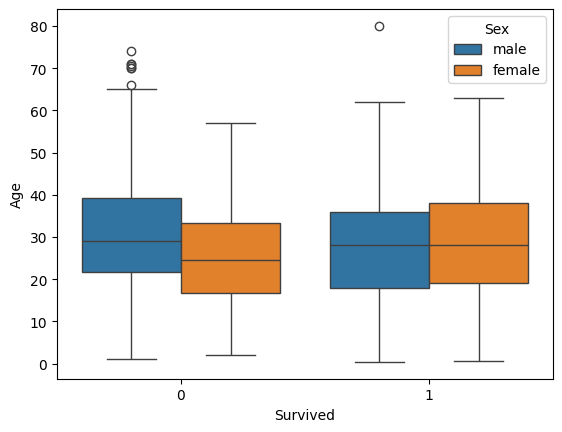

In [62]:
sns.boxplot(x='Survived',y='Age',hue='Sex',data=df_train);

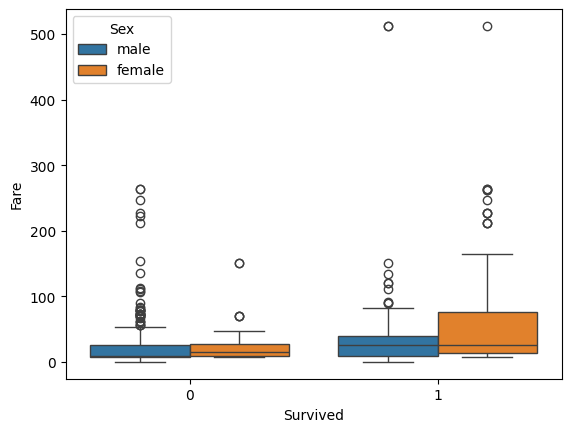

In [63]:
sns.boxplot(x='Survived',y='Fare',hue='Sex',data=df_train);

In [64]:
# Heatmap for feature variance

plt.figure(figsize=(12,10))
sns.heatmap(df_train.drop('PassengerId',axis=1).corr(), vmax=0.6, square=True, annot=True);

ValueError: could not convert string to float: 'Braund, Mr. Owen Harris'

<Figure size 1200x1000 with 0 Axes>

# Feature Engineering


### Feature 1: PClass

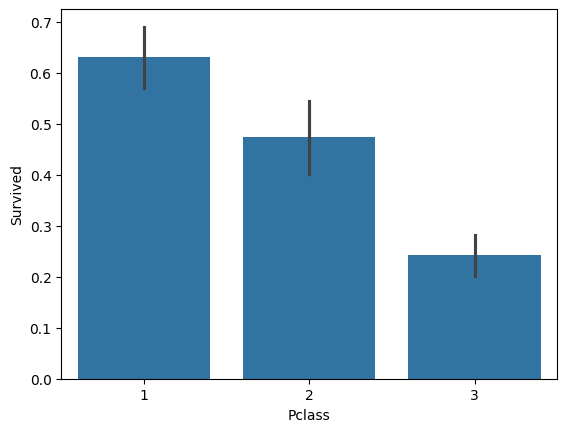

In [65]:
# Comparing Social class with survival rate
sns.barplot(x='Pclass', y='Survived', data=df_train);

In [66]:
## Converting pclass into three separate boolean variables
dummy_pclass = pd.get_dummies(df_train.Pclass, prefix='Pclass')
dummy_pclass.head()

,Pclass_1,Pclass_2,Pclass_3
0,False,False,True
1,True,False,False
2,False,False,True
3,True,False,False
4,False,False,True


In [67]:
# Merging these new classes with the main data.
df_train = df_train.merge(dummy_pclass, left_index=True, right_index=True)
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
 12  Pclass_1     891 non-null    bool   
 13  Pclass_2     891 non-null    bool   
 14  Pclass_3     891 non-null    bool   
dtypes: bool(3), float64(2), int64(5), object(5)
memory usage: 86.3+ KB


### Feature 2: Sex

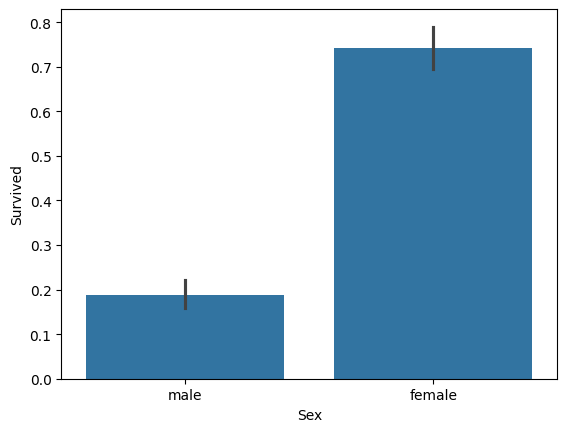

In [68]:
# Relation of gender with survival rate
sns.barplot(x='Sex', y='Survived', data=df_train);

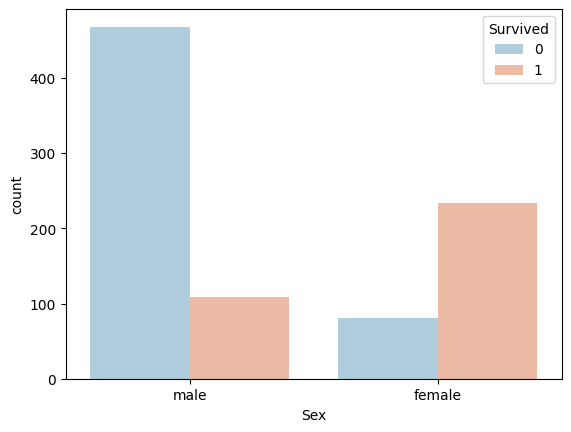

In [69]:
# Another way to look at the same data.
sns.countplot(x='Sex', hue='Survived', data=df_train, palette='RdBu_r');

In [70]:
df_train.Sex.replace(['male', 'female'], ['1', '0'], inplace=True)

/tmp/ipython-input-3681291395.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train.Sex.replace(['male', 'female'], ['1', '0'], inplace=True)


### Feature 3: Cabin

In [71]:
df_train['Cabin']

,Cabin
0,NaN
1,C85
2,NaN
3,C123
4,NaN
...,...
886,NaN
887,B42
888,NaN
889,C148


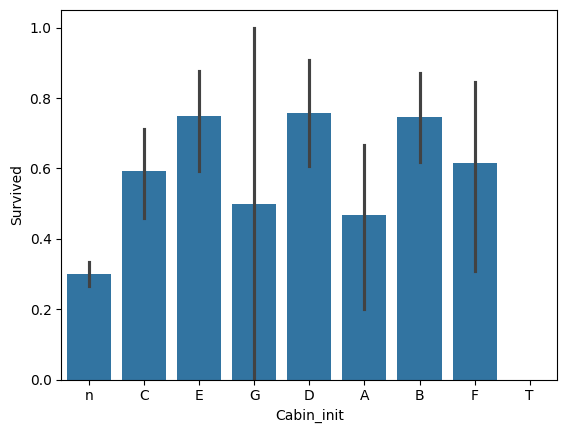

In [72]:
# Splitting the first letter to get class of the Cabin
df_train['Cabin_init'] = df_train['Cabin'].apply(lambda x : str(x)[0])
sns.barplot(x='Cabin_init', y='Survived', data=df_train);

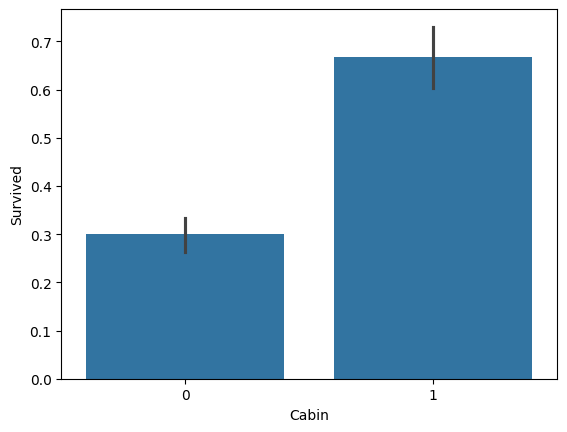

In [73]:
# Using NaN value as an information for the model.
df_train.loc[df_train.Cabin.notnull(), 'Cabin']=1
df_train.loc[df_train.Cabin.isnull(), 'Cabin']=0
sns.barplot(x='Cabin', y='Survived', data=df_train);

### Feature 4: Age

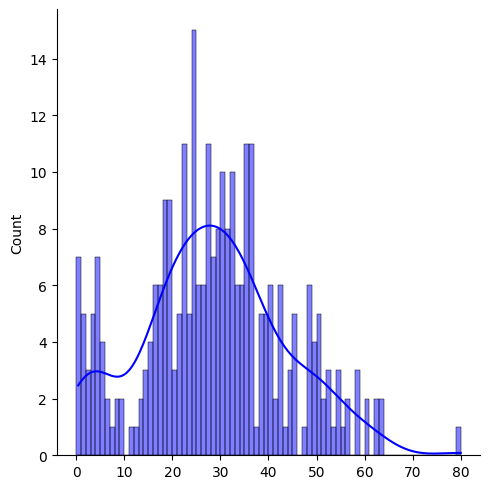

In [74]:
surv = df_train[df_train['Survived']==1]
sns.displot(surv['Age'].dropna().values, bins=range(0, 81, 1), kde=True, color='blue');

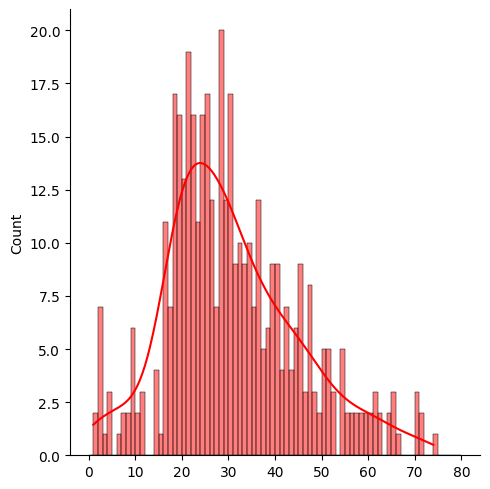

In [75]:
nosurv = df_train[df_train['Survived']==0]
sns.displot(nosurv['Age'].dropna().values, bins=range(0, 81, 1), kde=True, color='red');

# Exercise

#### Q1 - Imputation
**Imputation for null values in "Age".**   
Hint: One could simply replace it with the mean value or get creative and guess the correct age with the title in the `Name`.

In [76]:
## Replace this with a better technique
df_train.Age = df_train.Age.fillna(-0.5)


/tmp/ipython-input-966185645.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_age = df_train[["Age", "Survived"]].groupby(['Age'],as_index=False).mean()


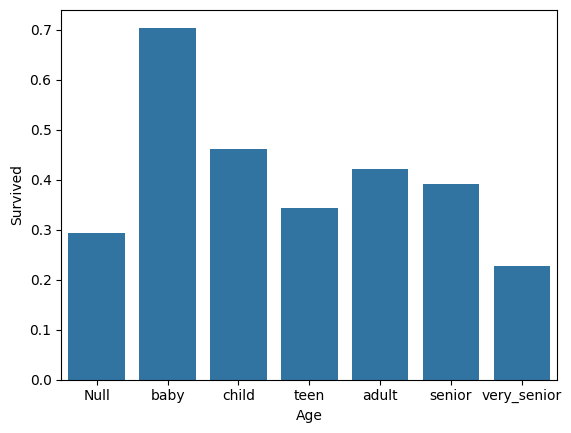

In [77]:
df_train.Age = pd.cut(df_train.Age, (-1, 0, 5, 15, 25, 40, 60,120),
                        labels=["Null", "baby","child", "teen", "adult", "senior", "very_senior"])

average_age = df_train[["Age", "Survived"]].groupby(['Age'],as_index=False).mean()
sns.barplot(x='Age', y='Survived', data=average_age);

### Feature 5: Family




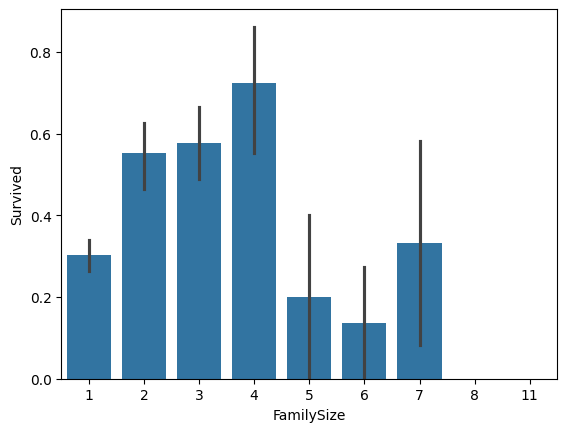

In [78]:
# Combining Siblings with Parents to get family size?
df_train['FamilySize'] = df_train['SibSp'] + df_train['Parch'] + 1
sns.barplot(x='FamilySize', y='Survived', data=df_train);

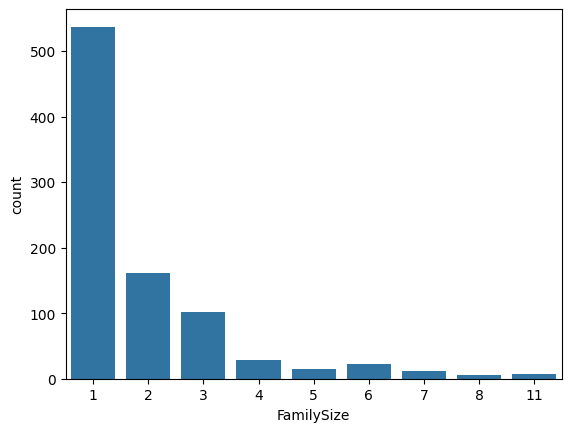

In [79]:
sns.countplot(x='FamilySize', data=df_train);

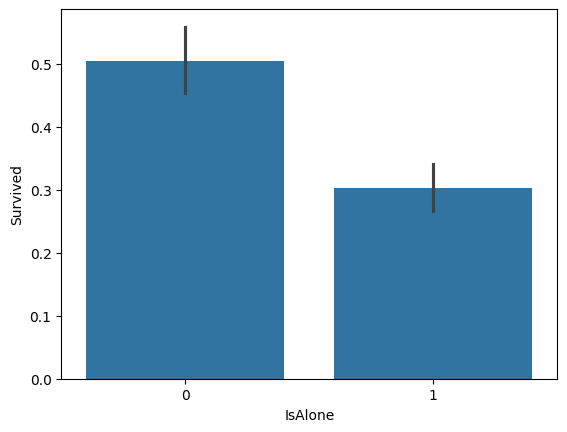

In [80]:
# The data is so skewed. Why not further modify it as a new column?
# A person without a family has lower chance of survival
df_train['IsAlone'] = 0
df_train.loc[df_train['FamilySize'] == 1, 'IsAlone'] = 1
sns.barplot(x='IsAlone', y='Survived', data=df_train);

### Feature 6: Embarked

In [81]:
df_train.groupby('Embarked').Survived.value_counts()

Embarked  Survived
C         1            93
          0            75
Q         0            47
          1            30
S         0           427
          1           217
Name: count, dtype: int64

### Feature 7,8,9
Modify these features as part of your exercise  
7.   Fare
8.   Name
9.   Ticket


# Exercise

#### Q2: Cleaning
Do Feature Engineering for the above 3 features and include them in the training data to further boost your accuracy.

# Pre-Processing


In [82]:
# Finalizing all the pre-processing steps we have seen above.
def pre_process(data):
  data['Sex'].replace(['male', 'female'], ['1', '0'], inplace=True)
  data = data.merge(pd.get_dummies(data['Pclass'], prefix='Pclass'), left_index=True, right_index=True)

  data.loc[data.Cabin.notnull(), 'Cabin']=1
  data.loc[data.Cabin.isnull(), 'Cabin']=0

  data.Age = pd.cut(data.Age.fillna(-0.5), (-1, 0, 5, 15, 25, 40, 60,120),
                        labels=[0, 1, 2, 3, 4, 5, 6])

  data['Embarked'] = data['Embarked'].fillna('S').replace(['C', 'Q', 'S'], ['1', '2', '3'])
  data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
  data['IsAlone'] = 0
  data.loc[data['FamilySize'] == 1, 'IsAlone'] = 1
  return data


df_train = pre_process(pd.read_csv("/content/train.csv"))
df_test = pre_process(pd.read_csv("/content/test.csv"))

cols_x = ['Sex', 'Age', 'Cabin', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked', 'IsAlone']
## Add other features like ['Fare', 'Name', 'Ticket] after completing Q2
cols_y = 'Survived'

/tmp/ipython-input-1068873953.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Sex'].replace(['male', 'female'], ['1', '0'], inplace=True)
/tmp/ipython-input-1068873953.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inpla

#Exercise

#### Q3 : PCA

(a) Perform a PCA on this preprocessed set of features (include different fields and try) and visualize them in 2D and/or 3D to see if it helps classify the data.

(b) Use a 90% variance PCA transformed features to fit a logistic regression model and see how it performs.

Do you think applying PCA is a good choice for this case?**bold text**

# Fit Model

In [83]:
from sklearn.model_selection import train_test_split

# split dataset to train and test
X_train, X_test, y_train, y_test = train_test_split(df_train[cols_x], df_train[cols_y],
                                                    test_size=0.3,
                                                    shuffle=True,
                                                    random_state=76 #  To guarantee that the split will always be the same
                                                    )

In [84]:
from sklearn.tree import DecisionTreeClassifier
cls = DecisionTreeClassifier()
cls.fit(X_train, y_train)
cls.score(X_test, y_test)

0.8022388059701493

# Hyperparameters tuning


In [85]:
# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import tree

# Ensembling
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier

# Metrics
from sklearn import preprocessing
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix

#### Initialization

In [86]:
result = pd.DataFrame(columns = ("Classifiers","Training","Testing"))
classifier, train_scores, test_scores = [],[],[]

#### Decision Tree

In [87]:
clf_tree = tree.DecisionTreeClassifier(
    #max_depth=3,\
    class_weight="balanced",\
    min_weight_fraction_leaf=0.01\
    )
clf_tree = clf_tree.fit(X_train,y_train)
classifier.append("DecisionTreeClassifier")
train_scores.append(clf_tree.score(X_train, y_train))
test_scores.append(clf_tree.score(X_test, y_test))

#### Logistic Regression

In [88]:
clf_log = LogisticRegression()
clf_log = clf_log.fit(X_train,y_train)
classifier.append("LogisticRegression")
train_scores.append(clf_log.score(X_train, y_train))
test_scores.append(clf_log.score(X_test, y_test))

# pd.DataFrame(list(zip(X_train.columns, np.transpose(clf_log.coef_))))

TypeError: can't multiply sequence by non-int of type 'float'

#### KNN

In [89]:
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train, y_train)
classifier.append("KNeighborsClassifier")
train_scores.append(knn.score(X_train, y_train))
test_scores.append(knn.score(X_test, y_test))

#### Support Vector Classifier

In [90]:
cf = SVC()
cf.fit(X_train, y_train)
classifier.append("SVM")
train_scores.append(cf.score(X_train, y_train))
test_scores.append(cf.score(X_test, y_test))

#### Perceptron

In [91]:
clf_pctr = Perceptron(
    class_weight='balanced'
    )
clf_pctr = clf_pctr.fit(X_train,y_train)
classifier.append("Perceptron")
train_scores.append(clf_pctr.score(X_train, y_train))
test_scores.append(clf_pctr.score(X_test, y_test))

TypeError: can't multiply sequence by non-int of type 'float'

#### Random Forest

In [ ]:
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train, y_train)
classifier.append("RandomForestClassifier")
train_scores.append(random_forest.score(X_train, y_train))
test_scores.append(random_forest.score(X_test, y_test))

#### Extra Tree

In [ ]:
clf_ext = ExtraTreesClassifier(
    max_features='auto',
    bootstrap=True,
    oob_score=True,
    n_estimators=1000,
    max_depth=None,
    min_samples_split=10
    #class_weight="balanced",
    #min_weight_fraction_leaf=0.02
    )
clf_ext = clf_ext.fit(X_train,y_train)
classifier.append("ExtraTreesClassifier")
train_scores.append(clf_ext.score(X_train, y_train))
test_scores.append(clf_ext.score(X_test, y_test))

#### Ada Boost

In [ ]:
clf_ada = AdaBoostClassifier(n_estimators=400, learning_rate=0.1)
clf_ada.fit(X_train,y_train)
classifier.append("AdaBoostClassifier")
train_scores.append(clf_ada.score(X_train, y_train))
test_scores.append(clf_ada.score(X_test, y_test))

#### Results

In [ ]:
for i,text in enumerate(classifier):
    result.loc[i+1] = [text,np.around(train_scores[i]*100, decimals = 1),np.around(test_scores[i]*100, decimals=1)]
result

# Ensemble Methods

In [ ]:
# Trying to improve with the ensemble of all predictors

clf_vote = VotingClassifier(
    estimators=[
        ('knn', knn), # KNN
        ('svm', cf), # SVM
        ('dt', clf_tree), # Decision Tree
        ('extra', clf_ext), #  Extra Tree
        ('logistic', clf_log), # Logistic Regression
        ('adaboost', clf_ada)
        ],
    weights=[1, 1, 1, 1, 1, 1],
    voting='hard')
clf_vote.fit(X_train, y_train)
clf_vote.score(X_test, y_test)

# Cross Validation

In [ ]:
scores = cross_val_score(clf_vote, df_train[cols_x], df_train[cols_y], cv=5, scoring='accuracy')
print("Voting: Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std()))

# Submission File

In [ ]:
clf_vote.fit(df_train[cols_x], df_train[cols_y])
y_pred = clf_vote.predict(df_test[cols_x])

In [ ]:
dummy = pd.DataFrame()
dummy["PassengerId"] = df_test["PassengerId"]
dummy["Survived"]=clf_vote.predict(df_test[cols_x])
dummy.to_csv("submission.csv", sep=',' ,index=False)

This submission file gives an accuracy of 76% at https://www.kaggle.com/c/titanic/submit